In [28]:
# Step 3: Data Preprocessing

import pandas as pd
import numpy as np

# Load the original MODIS dataset
modis = pd.read_csv("hyderabad_modis_heat.csv")

# Display dataset information
print("Dataset Shape:", modis.shape)

print("\nDataset Columns:")
print(modis.columns.tolist())

print("\nFirst 5 Rows:")
display(modis.head())

print("\nDataset Information:")
modis.info()

Dataset Shape: (1326, 5)

Dataset Columns:
['pixel_id', 'latitude', 'longitude', 'daytime_temp_c', 'nighttime_temp_c']

First 5 Rows:


,pixel_id,latitude,longitude,daytime_temp_c,nighttime_temp_c
0,0,17.252145,78.301652,36.602941,20.399730
1,1,17.252145,78.310635,37.113429,20.463514
2,2,17.252145,78.319618,37.561429,20.448333
3,3,17.252145,78.328601,37.337429,20.488919
4,4,17.252145,78.337584,36.722571,20.528919



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1326 entries, 0 to 1325
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   pixel_id          1326 non-null   int64  
 1   latitude          1326 non-null   float64
 2   longitude         1326 non-null   float64
 3   daytime_temp_c    1326 non-null   float64
 4   nighttime_temp_c  1326 non-null   float64
dtypes: float64(4), int64(1)
memory usage: 51.9 KB


In [29]:
# Check missing values

print("Missing Values in Each Column:")
print(modis.isnull().sum())

print("\nTotal Missing Values:")
print(modis.isnull().sum().sum())

Missing Values in Each Column:
pixel_id            0
latitude            0
longitude           0
daytime_temp_c      0
nighttime_temp_c    0
dtype: int64

Total Missing Values:
0


In [30]:
# Check duplicate records

print("Total Duplicate Rows:", modis.duplicated().sum())

print("\nDuplicate Pixel IDs:", modis['pixel_id'].duplicated().sum())

Total Duplicate Rows: 0

Duplicate Pixel IDs: 0


In [31]:
# Check data types

print("Data Types of Each Column:")
print(modis.dtypes)

print("\nDataset Information:")
modis.info()

Data Types of Each Column:
pixel_id              int64
latitude            float64
longitude           float64
daytime_temp_c      float64
nighttime_temp_c    float64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1326 entries, 0 to 1325
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   pixel_id          1326 non-null   int64  
 1   latitude          1326 non-null   float64
 2   longitude         1326 non-null   float64
 3   daytime_temp_c    1326 non-null   float64
 4   nighttime_temp_c  1326 non-null   float64
dtypes: float64(4), int64(1)
memory usage: 51.9 KB


In [32]:
# Check infinite values

print("Infinite Values:")
print(np.isinf(modis.select_dtypes(include=np.number)).sum())

# Check minimum and maximum values
print("\nMinimum Values:")
print(modis.min(numeric_only=True))

print("\nMaximum Values:")
print(modis.max(numeric_only=True))

# Statistical summary
print("\nStatistical Summary:")
display(modis.describe())

Infinite Values:
pixel_id            0
latitude            0
longitude           0
daytime_temp_c      0
nighttime_temp_c    0
dtype: int64

Minimum Values:
pixel_id             0.000000
latitude            17.252145
longitude           78.301652
daytime_temp_c      26.644737
nighttime_temp_c    19.846757
dtype: float64

Maximum Values:
pixel_id            1325.000000
latitude              17.548589
longitude             78.643012
daytime_temp_c        37.593243
nighttime_temp_c      25.210000
dtype: float64

Statistical Summary:


,pixel_id,latitude,longitude,daytime_temp_c,nighttime_temp_c
count,1326.000000,1326.000000,1326.000000,1326.000000,1326.000000
mean,662.500000,17.400367,78.472332,34.323556,22.473464
std,382.927539,0.088164,0.101140,1.299366,1.225156
min,0.000000,17.252145,78.301652,26.644737,19.846757
25%,331.250000,17.324010,78.382500,33.789167,21.442143
50%,662.500000,17.400367,78.472332,34.312162,22.412270
75%,993.750000,17.476724,78.562163,34.978026,23.442500
max,1325.000000,17.548589,78.643012,37.593243,25.210000


In [33]:
# Final Data Preprocessing Verification

print("Dataset Shape:", modis.shape)

print("Missing Values:", modis.isnull().sum().sum())

print("Duplicate Rows:", modis.duplicated().sum())

print("Infinite Values:",
      np.isinf(modis.select_dtypes(include=np.number)).sum().sum())

print("\nDataset is ready for Exploratory Data Analysis.")

Dataset Shape: (1326, 5)
Missing Values: 0
Duplicate Rows: 0
Infinite Values: 0

Dataset is ready for Exploratory Data Analysis.


In [34]:
# Step 4: Exploratory Data Analysis

# Select input features
X_modis = modis[
    ['latitude', 'longitude',
     'daytime_temp_c', 'nighttime_temp_c']
]

# Statistical summary
print("Statistical Summary of MODIS Input Features:")
display(X_modis.describe())

Statistical Summary of MODIS Input Features:


,latitude,longitude,daytime_temp_c,nighttime_temp_c
count,1326.000000,1326.000000,1326.000000,1326.000000
mean,17.400367,78.472332,34.323556,22.473464
std,0.088164,0.101140,1.299366,1.225156
min,17.252145,78.301652,26.644737,19.846757
25%,17.324010,78.382500,33.789167,21.442143
50%,17.400367,78.472332,34.312162,22.412270
75%,17.476724,78.562163,34.978026,23.442500
max,17.548589,78.643012,37.593243,25.210000


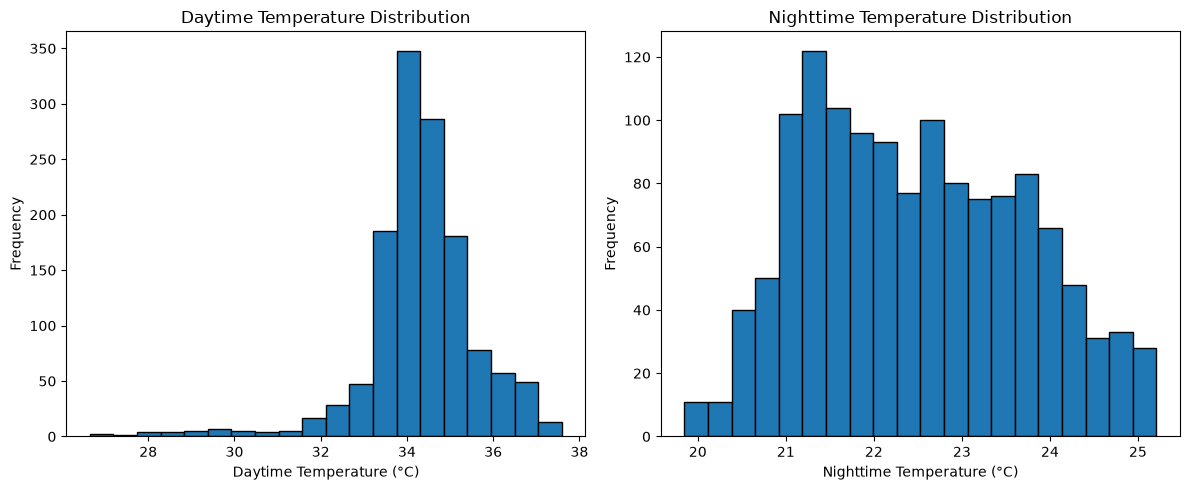

In [35]:
# Temperature Distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Daytime temperature
plt.subplot(1, 2, 1)
plt.hist(modis['daytime_temp_c'], bins=20, edgecolor='black')
plt.title('Daytime Temperature Distribution')
plt.xlabel('Daytime Temperature (°C)')
plt.ylabel('Frequency')

# Nighttime temperature
plt.subplot(1, 2, 2)
plt.hist(modis['nighttime_temp_c'], bins=20, edgecolor='black')
plt.title('Nighttime Temperature Distribution')
plt.xlabel('Nighttime Temperature (°C)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

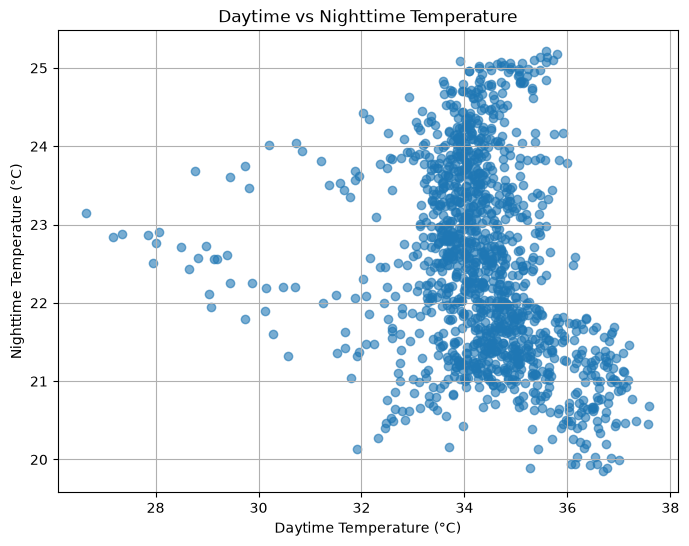

In [36]:
# Daytime vs Nighttime Temperature

plt.figure(figsize=(8, 6))

plt.scatter(
    modis['daytime_temp_c'],
    modis['nighttime_temp_c'],
    alpha=0.6
)

plt.title('Daytime vs Nighttime Temperature')
plt.xlabel('Daytime Temperature (°C)')
plt.ylabel('Nighttime Temperature (°C)')

plt.grid(True)
plt.show()

Correlation Matrix:


,latitude,longitude,daytime_temp_c,nighttime_temp_c
latitude,1.000000e+00,-5.200049e-13,-0.266242,0.282506
longitude,-5.200049e-13,1.000000e+00,0.294720,-0.085590
daytime_temp_c,-2.662417e-01,2.947203e-01,1.000000,-0.274216
nighttime_temp_c,2.825061e-01,-8.559019e-02,-0.274216,1.000000


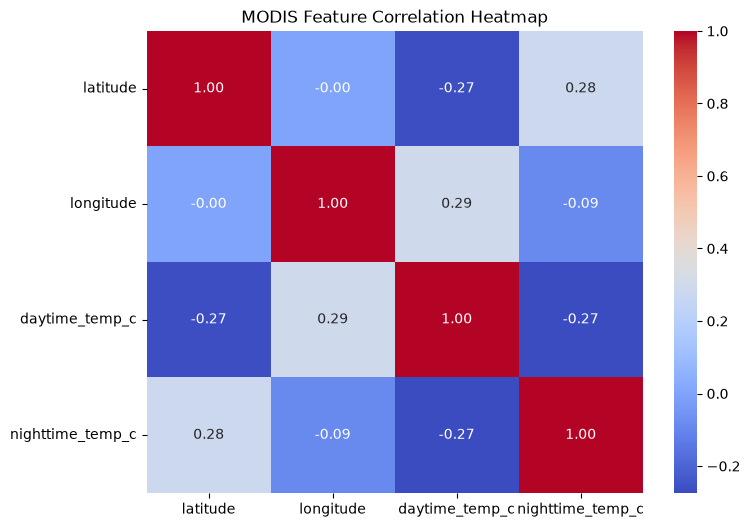

In [37]:
# Correlation Analysis

import seaborn as sns

correlation_matrix = X_modis.corr()

print("Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('MODIS Feature Correlation Heatmap')
plt.show()

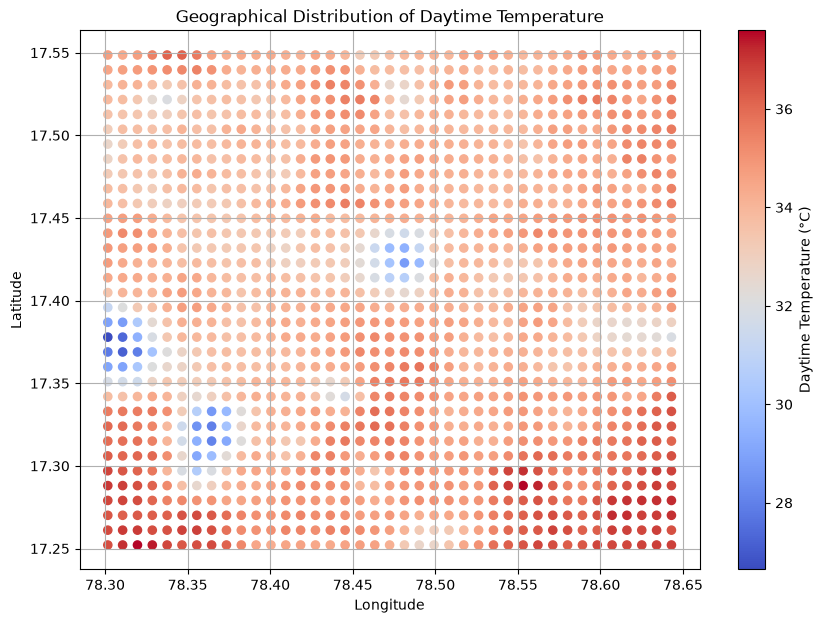

In [38]:
# Geographical Heat Distribution

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    modis['longitude'],
    modis['latitude'],
    c=modis['daytime_temp_c'],
    cmap='coolwarm',
    s=35
)

plt.colorbar(scatter, label='Daytime Temperature (°C)')

plt.title('Geographical Distribution of Daytime Temperature')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.grid(True)
plt.show()

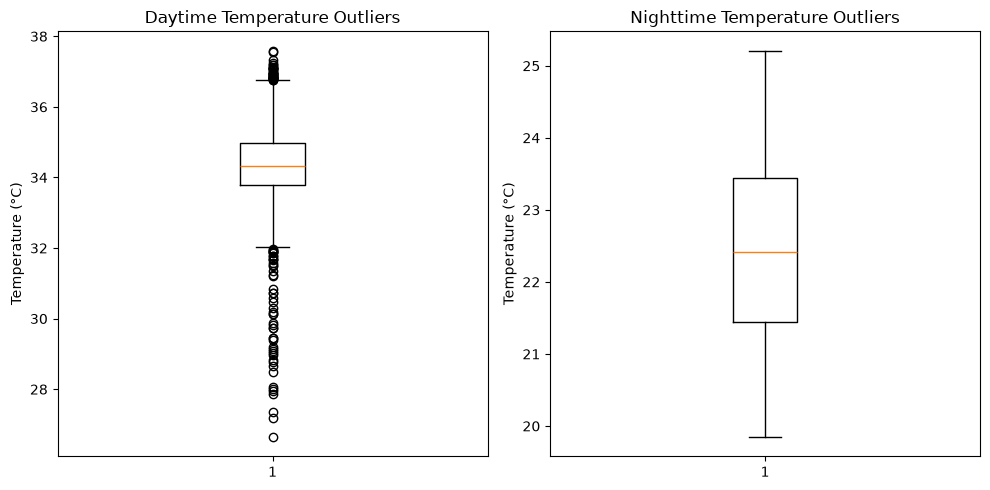

In [39]:
# Outlier Analysis using Boxplots

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.boxplot(modis['daytime_temp_c'])
plt.title('Daytime Temperature Outliers')
plt.ylabel('Temperature (°C)')

plt.subplot(1, 2, 2)
plt.boxplot(modis['nighttime_temp_c'])
plt.title('Nighttime Temperature Outliers')
plt.ylabel('Temperature (°C)')

plt.tight_layout()
plt.show()

In [40]:
# Step 5: Feature Engineering

# Select relevant input features
X_modis = modis[
    ['latitude',
     'longitude',
     'daytime_temp_c',
     'nighttime_temp_c']
].copy()

print("Selected Features:")
print(X_modis.columns.tolist())

print("\nInput Dataset Shape:", X_modis.shape)

print("\nFirst 5 Rows:")
display(X_modis.head())

Selected Features:
['latitude', 'longitude', 'daytime_temp_c', 'nighttime_temp_c']

Input Dataset Shape: (1326, 4)

First 5 Rows:


,latitude,longitude,daytime_temp_c,nighttime_temp_c
0,17.252145,78.301652,36.602941,20.399730
1,17.252145,78.310635,37.113429,20.463514
2,17.252145,78.319618,37.561429,20.448333
3,17.252145,78.328601,37.337429,20.488919
4,17.252145,78.337584,36.722571,20.528919


In [41]:
# Feature Scaling using StandardScaler

from sklearn.preprocessing import StandardScaler

scaler_modis = StandardScaler()

X_modis_scaled = scaler_modis.fit_transform(X_modis)

# Convert scaled data into DataFrame
X_modis_scaled = pd.DataFrame(
    X_modis_scaled,
    columns=X_modis.columns
)

print("Scaled Dataset Shape:", X_modis_scaled.shape)

print("\nFirst 5 Scaled Rows:")
display(X_modis_scaled.head())

print("\nScaled Feature Means:")
print(X_modis_scaled.mean().round(4))

Scaled Dataset Shape: (1326, 4)

First 5 Scaled Rows:


,latitude,longitude,daytime_temp_c,nighttime_temp_c
0,-1.681836,-1.688194,1.754890,-1.693267
1,-1.681836,-1.599342,2.147912,-1.641185
2,-1.681836,-1.510490,2.492826,-1.653580
3,-1.681836,-1.421637,2.320369,-1.620441
4,-1.681836,-1.332785,1.846993,-1.587780



Scaled Feature Means:
latitude           -0.0
longitude          -0.0
daytime_temp_c      0.0
nighttime_temp_c   -0.0
dtype: float64


In [42]:
# Step 7: Model Training - K-Means Clustering

from sklearn.cluster import KMeans

# Create K-Means model
kmeans_modis = KMeans(
    n_clusters=7,
    n_init=10,
    random_state=42
)

# Train the model
modis_labels = kmeans_modis.fit_predict(X_modis_scaled)

# Add cluster labels to the dataset
modis_clustered = modis.copy()
modis_clustered['Cluster'] = modis_labels

print("K-Means Model Training Completed!")

print("\nCluster Distribution:")
print(modis_clustered['Cluster'].value_counts().sort_index())

print("\nFirst 10 Cluster Assignments:")
display(modis_clustered.head(10))

K-Means Model Training Completed!

Cluster Distribution:
Cluster
0    133
1    301
2     51
3    329
4    201
5     65
6    246
Name: count, dtype: int64

First 10 Cluster Assignments:


,pixel_id,latitude,longitude,daytime_temp_c,nighttime_temp_c,Cluster
0,0,17.252145,78.301652,36.602941,20.399730,5
1,1,17.252145,78.310635,37.113429,20.463514,5
2,2,17.252145,78.319618,37.561429,20.448333,5
3,3,17.252145,78.328601,37.337429,20.488919,5
4,4,17.252145,78.337584,36.722571,20.528919,5
5,5,17.252145,78.346568,36.382000,20.644444,5
6,6,17.252145,78.355551,36.567143,20.802973,5
7,7,17.252145,78.364534,36.635143,21.002105,5
8,8,17.252145,78.373517,36.163143,21.340811,5
9,9,17.252145,78.382500,35.308857,21.539730,4


In [43]:
# Step 7.2: PCA Training

from sklearn.decomposition import PCA

# Create PCA model
pca_modis = PCA(n_components=2)

# Fit and transform scaled data
X_modis_pca = pca_modis.fit_transform(X_modis_scaled)

# Convert PCA results into DataFrame
pca_modis_df = pd.DataFrame(
    X_modis_pca,
    columns=['PC1', 'PC2']
)

print("PCA Training Completed!")

print("\nPCA Dataset Shape:", pca_modis_df.shape)

print("\nFirst 5 PCA Rows:")
display(pca_modis_df.head())

print("\nExplained Variance Ratio:")
print(pca_modis.explained_variance_ratio_)

print("\nTotal Explained Variance:",
      pca_modis.explained_variance_ratio_.sum())

PCA Training Completed!

PCA Dataset Shape: (1326, 2)

First 5 PCA Rows:


,PC1,PC2
0,2.173654,-2.282506
1,2.413075,-2.110272
2,2.657639,-1.968202
3,2.568006,-1.927597
4,2.298206,-1.954141



Explained Variance Ratio:
[0.40775483 0.26281264]

Total Explained Variance: 0.6705674741858934


In [44]:
# Step 7.3: Generate Heat Intensity Labels

# Cluster to heat category mapping
cluster_mapping_modis = {
    2: 'Low',
    6: 'Low',
    4: 'Low',
    5: 'Medium',
    1: 'Medium',
    0: 'High',
    3: 'High'
}

# Create a separate working dataset
modis_supervised = modis.copy()

# Add cluster labels
modis_supervised['Cluster'] = modis_labels

# Generate heat intensity categories
modis_supervised['Heat_Intensity'] = (
    modis_supervised['Cluster'].map(cluster_mapping_modis)
)

print("Heat Intensity Labels Generated!")

print("\nHeat Intensity Distribution:")
print(modis_supervised['Heat_Intensity'].value_counts())

print("\nFirst 10 Rows:")
display(modis_supervised.head(10))

Heat Intensity Labels Generated!

Heat Intensity Distribution:
Heat_Intensity
Low       498
High      462
Medium    366
Name: count, dtype: int64

First 10 Rows:


,pixel_id,latitude,longitude,daytime_temp_c,nighttime_temp_c,Cluster,Heat_Intensity
0,0,17.252145,78.301652,36.602941,20.399730,5,Medium
1,1,17.252145,78.310635,37.113429,20.463514,5,Medium
2,2,17.252145,78.319618,37.561429,20.448333,5,Medium
3,3,17.252145,78.328601,37.337429,20.488919,5,Medium
4,4,17.252145,78.337584,36.722571,20.528919,5,Medium
5,5,17.252145,78.346568,36.382000,20.644444,5,Medium
6,6,17.252145,78.355551,36.567143,20.802973,5,Medium
7,7,17.252145,78.364534,36.635143,21.002105,5,Medium
8,8,17.252145,78.373517,36.163143,21.340811,5,Medium
9,9,17.252145,78.382500,35.308857,21.539730,4,Low


In [45]:
# Step 7.4: Prepare X and y

# Input features
X = modis_supervised[
    ['latitude',
     'longitude',
     'daytime_temp_c',
     'nighttime_temp_c']
]

# Target variable
y = modis_supervised['Heat_Intensity']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
display(X.head())

print("\nTarget Labels:")
print(y.head())

print("\nTarget Categories:")
print(y.unique())

Input Features Shape: (1326, 4)
Target Variable Shape: (1326,)

Input Features:


,latitude,longitude,daytime_temp_c,nighttime_temp_c
0,17.252145,78.301652,36.602941,20.399730
1,17.252145,78.310635,37.113429,20.463514
2,17.252145,78.319618,37.561429,20.448333
3,17.252145,78.328601,37.337429,20.488919
4,17.252145,78.337584,36.722571,20.528919



Target Labels:
0    Medium
1    Medium
2    Medium
3    Medium
4    Medium
Name: Heat_Intensity, dtype: str

Target Categories:
<StringArray>
['Medium', 'Low', 'High']
Length: 3, dtype: str


In [46]:
# Step 7.5: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (1060, 4)
Testing Data Shape: (266, 4)

Training Target Distribution:
Heat_Intensity
Low       398
High      369
Medium    293
Name: count, dtype: int64

Testing Target Distribution:
Heat_Intensity
Low       100
High       93
Medium     73
Name: count, dtype: int64


In [47]:
# Step 7.6: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler_supervised_modis = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler_supervised_modis.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler_supervised_modis.transform(X_test)

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nFirst 5 Scaled Training Rows:")
display(pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
).head())

Training Data Shape: (1060, 4)
Testing Data Shape: (266, 4)

First 5 Scaled Training Rows:


,latitude,longitude,daytime_temp_c,nighttime_temp_c
0,0.769479,-1.170060,-0.409952,0.143466
1,-0.147781,-0.990428,-0.484844,0.120808
2,1.177150,-0.182088,0.143466,0.542428
3,-1.574630,-0.631166,0.776212,-1.138016
4,-1.676547,1.075330,1.510288,-1.132925


In [48]:
# Step 7.7: Train All Supervised Algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Create all six models
models_modis = {
    'Logistic Regression': LogisticRegression(
        random_state=42, max_iter=1000
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        random_state=42, n_estimators=100
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'SVM': SVC(
        random_state=42
    ),

    'Gaussian Naive Bayes': GaussianNB()
}

# Train and predict using all models
predictions_modis = {}

for name, model in models_modis.items():

    # Train model
    model.fit(X_train_scaled, y_train)

    # Generate predictions
    predictions = model.predict(X_test_scaled)

    # Store predictions
    predictions_modis[name] = predictions

    print(name, "- Training Completed!")

print("\nAll Six Supervised Models Trained Successfully!")

Logistic Regression - Training Completed!
Decision Tree - Training Completed!
Random Forest - Training Completed!
KNN - Training Completed!
SVM - Training Completed!
Gaussian Naive Bayes - Training Completed!

All Six Supervised Models Trained Successfully!


In [49]:
# Step 8: Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results_modis = []

for name, predictions in predictions_modis.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, average='weighted'
    )

    recall = recall_score(
        y_test, predictions, average='weighted'
    )

    f1 = f1_score(
        y_test, predictions, average='weighted'
    )

    results_modis.append({
        'Algorithm': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

results_modis_df = pd.DataFrame(results_modis)

print("MODIS MODEL EVALUATION RESULTS:")

display(
    results_modis_df.sort_values(
        by='Accuracy',
        ascending=False
    ).reset_index(drop=True)
)

MODIS MODEL EVALUATION RESULTS:


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.969925,0.969963,0.969925,0.969923
1,SVM,0.969925,0.971564,0.969925,0.969955
2,KNN,0.962406,0.962638,0.962406,0.962227
3,Random Forest,0.962406,0.963212,0.962406,0.962401
4,Logistic Regression,0.894737,0.894652,0.894737,0.894430
5,Gaussian Naive Bayes,0.766917,0.773758,0.766917,0.764981


In [52]:
from sklearn.metrics import accuracy_score

comparison_modis = []

for name in models_modis:

    original_accuracy = accuracy_score(
        y_test,
        predictions_modis[name]
    )

    tuned_predictions = tuned_models_modis[name].predict(
        X_test_scaled
    )

    tuned_accuracy = accuracy_score(
        y_test,
        tuned_predictions
    )

    comparison_modis.append({
        'Algorithm': name,
        'Original Accuracy': original_accuracy,
        'Tuned Accuracy': tuned_accuracy
    })

comparison_modis_df = pd.DataFrame(comparison_modis)

display(comparison_modis_df.sort_values(
    by='Tuned Accuracy',
    ascending=False
).reset_index(drop=True))

,Algorithm,Original Accuracy,Tuned Accuracy
0,SVM,0.969925,0.973684
1,Random Forest,0.962406,0.962406
2,KNN,0.962406,0.962406
3,Decision Tree,0.969925,0.958647
4,Logistic Regression,0.894737,0.890977
5,Gaussian Naive Bayes,0.766917,0.766917


In [53]:
import joblib
import os

# Create folder to store MODIS models
os.makedirs("MODIS_Saved_Models", exist_ok=True)

# Save all six tuned models
for name, model in tuned_models_modis.items():

    filename = name.replace(" ", "_") + ".pkl"

    joblib.dump(
        model,
        os.path.join("MODIS_Saved_Models", filename)
    )

# Save feature scaler
joblib.dump(
    scaler_supervised_modis,
    "MODIS_Saved_Models/modis_scaler.pkl"
)

# Save best model (SVM)
best_model_modis = tuned_models_modis['SVM']

joblib.dump(
    best_model_modis,
    "MODIS_Saved_Models/best_modis_model.pkl"
)

print("All six tuned models saved successfully!")
print("Feature scaler saved successfully!")
print("Best MODIS model (SVM) saved successfully!")

All six tuned models saved successfully!
Feature scaler saved successfully!
Best MODIS model (SVM) saved successfully!


In [54]:
from sklearn.metrics import silhouette_score

# K-Means Evaluation
wcss_modis = kmeans_modis.inertia_

silhouette_modis = silhouette_score(
    X_modis_scaled,
    modis_labels
)

print("MODIS K-MEANS EVALUATION")
print("--------------------------------")
print("WCSS (Inertia):", wcss_modis)
print("Silhouette Score:", silhouette_modis)

MODIS K-MEANS EVALUATION
--------------------------------
WCSS (Inertia): 1394.9002861402714
Silhouette Score: 0.35525894917396417
